In [8]:
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 


In [2]:
X, y = make_moons(n_samples=1000, noise=0.05)
dbscan = DBSCAN(eps=0.05, min_samples=5)
dbscan.fit(X)

,eps,0.05
,min_samples,5
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


In [5]:
print(dbscan.labels_) #-1 means noise in the dataset 
print(dbscan.core_sample_indices_)

[ 0  1  4  2  1  3  0 -1 -1  3  3  4  5 -1  0  1  6  3 -1  5  5  2  1  0
  3  3  3  5  2  2  4  2  5  3  3  3  4  5  5  6  0  3  3  7  5  2  3  3
  7 -1  5  3  5  1  0  4  1  1  6  2 -1  3  6  5  6  3  1  0  0  3  0  3
 -1  1  1  3 -1 -1 -1  4  1 -1  1  3  6  3  3  3  2  5  4  5  5  7  3  5
  5  4  1  6  3  6  7  1  6  0  3  3  2  3  5  8  3  1  2  0  5  6  1 -1
  4  1  4  4 -1  5 -1  4  3  3  5  2  6  6  5  3  3 -1  4  2  3  1  6  1
  2  3  3  1  1 -1  3  6  3  3  0  1  3  1  6  4  1  4  5  2  1  3  3  2
 -1  2  3  1  2  1  3  1  3  3  5  6  5  1  1  7  3  5  3  5  1  1  1  3
  3  0  5  1  4  3 -1  5  1  4  3  1  3  1  1  1  3  3  4  2  5  3  1  2
  1  1  1  1  2 -1  1  1  1  3  5  5  0  0  2  6  4  3  1  2  1  1  4  5
  6  3  2  2  3  1  2  5  1  4 -1  1 -1  6 -1  2  5  9  3  1  2  1  4 -1
  6  4  3  9  2  3 -1  1  3  4  3  1  3  3  5  8  1  5  2  3 -1  1  1  6
  4  2  1  4  5  5  1  4  2  1  2  1  1  4 -1  2  4  3  1  5  5  1  1  2
  1  6  5  6  2  2  8  2  1  4  3  3  3  4  1  1  2

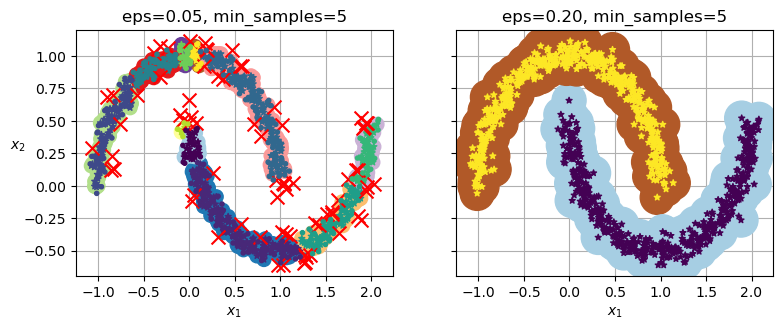

In [10]:
def plot_dbscan(dbscan, X, size, show_xlabels=True, show_ylabels=True):
    core_mask = np.zeros_like(dbscan.labels_, dtype=bool)
    core_mask[dbscan.core_sample_indices_] = True
    anomalies_mask = dbscan.labels_ == -1
    non_core_mask = ~(core_mask | anomalies_mask)

    cores = dbscan.components_
    anomalies = X[anomalies_mask]
    non_cores = X[non_core_mask]
    
    plt.scatter(cores[:, 0], cores[:, 1],
                c=dbscan.labels_[core_mask], marker='o', s=size, cmap="Paired")
    plt.scatter(cores[:, 0], cores[:, 1], marker='*', s=20,
                c=dbscan.labels_[core_mask])
    plt.scatter(anomalies[:, 0], anomalies[:, 1],
                c="r", marker="x", s=100)
    plt.scatter(non_cores[:, 0], non_cores[:, 1],
                c=dbscan.labels_[non_core_mask], marker=".")
    if show_xlabels:
        plt.xlabel("$x_1$")
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", rotation=0)
    else:
        plt.tick_params(labelleft=False)
    plt.title(f"eps={dbscan.eps:.2f}, min_samples={dbscan.min_samples}")
    plt.grid()
    plt.gca().set_axisbelow(True)

dbscan2 = DBSCAN(eps=0.2)
dbscan2.fit(X)

plt.figure(figsize=(9, 3.2))

plt.subplot(121)
plot_dbscan(dbscan, X, size=100)

plt.subplot(122)
plot_dbscan(dbscan2, X, size=600, show_ylabels=False)

plt.show()